In [1]:
import sys
sys.path.append("/home/macbuse/miniconda3/lib/python3.11/site-packages")

import numpy as np
import itertools

import matplotlib as mpl

mpl.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{amsmath}",
})

import matplotlib.pyplot as plt
import matplotlib.patches as patches


def x2c(x):
    c,r = .5*(x - 1/x),.5*abs(x + 1/x)
    return c,r


def add_circle(
    ax, 
    center_x, center_y, radius, 
    fill=True, linewidth=1,
    **kwargs
):
    """Helper to add a Euclidean circle 
    patch to the upper half-plane.
    """
    circle = patches.Circle(
        (center_x, center_y), 
        radius, 
        fill=fill, 
        **kwargs
    )
    ax.add_patch(circle)

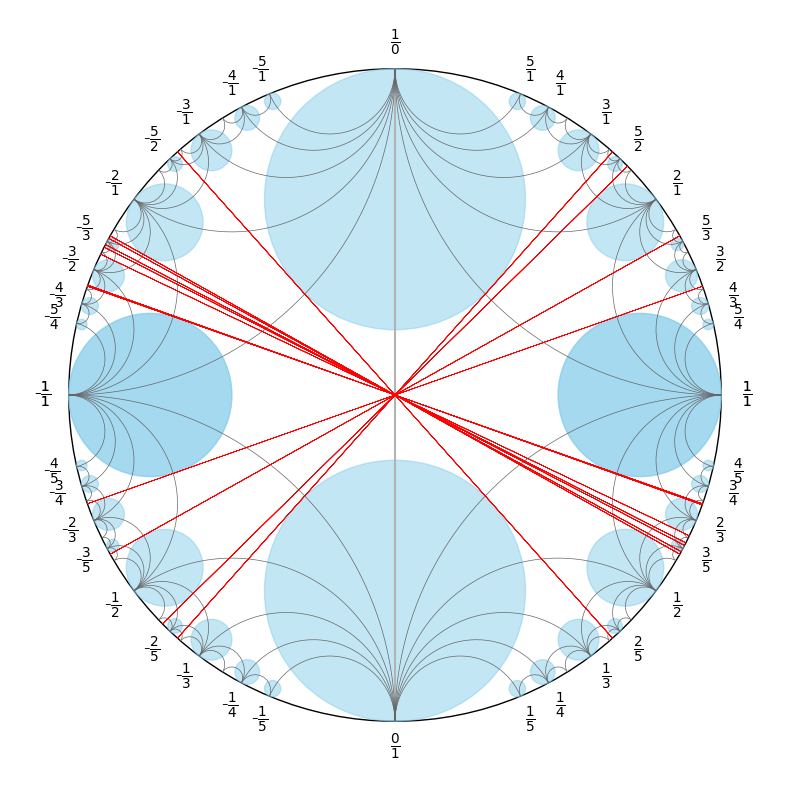

In [2]:
def farey(n: int) -> np.ndarray:
    """Return Farey-type mediant subdivisions of [-1/1, 0/1, 1/1] at depth n."""
    F = np.array([[-1, 1], [0, 1], [1, 1]], dtype=int)
    for _ in range(n):
        nxt = np.empty((2 * len(F) - 1, 2), dtype=int)
        nxt[::2] = F
        nxt[1::2] = F[:-1] + F[1:]
        F = nxt
    return F
    
def cayley(z: complex | np.ndarray) -> complex | np.ndarray:
    """Map the upper half-plane to the unit disk (-1 -> -1, 1 -> 1, 0 -> -i)."""
    return 1j * (z - 1j) / (z + 1j)

def seg2arc(a,b):
    '''a,b points on the unit circle
    return the center, radius and angle
    for the Poincaré geodesic from a to b
    '''
    y = abs(a-b)/2
    dd = 1/np.sqrt(1 - y**2)
    r = y*dd
    return dd*(a+b)/abs(a+b), r, np.arccos(y)

from matplotlib.collections import LineCollection

def geodesic_arc(a: complex, b: complex, 
                 min_delta: float = 0.01) -> np.ndarray | None:
    """Return (N, 2) array of points along the Poincaré geodesic from a to b."""
    delta = abs(a - b)
    if delta < min_delta: return None
    cc, r, theta = seg2arc(a, b)
    T = np.linspace(-theta, theta, max(12, int(100 * delta)))
    arc = cc - r * (cc / abs(cc)) * np.exp(1j * T)
    return np.column_stack((arc.real, arc.imag))



# housekeeping
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect('equal')
ax.set_xlim(-1.18, 1.18)
ax.set_ylim(-1.18, 1.18)
ax.axis('off')

# draw the unit circle and a diameter
add_circle(ax, 0,0,1, fill=False)
ax.plot([0,0], [1,-1],'.7')


farey_seq  = farey(4).T
#map fractions to the circle
Z =  cayley(farey_seq[0]/farey_seq[1]) 


# Collect all arcs across Farey levels
arcs = []
level = Z
while len(level) > 2:
    for a, b in zip(level, level[1:]):
        pts = geodesic_arc(a, b)
        if pts is not None:
            arcs.extend([pts, -pts])  # both halves of the disc
    level = level[::2]

ax.add_collection(LineCollection(arcs, colors="0.4", linewidths=0.5))


#this is the label string
rlabel = r"{}$\frac{{{}}}{{{}}}$"
for numerator, denominator  in farey_seq.T:
    
    # no big denominators
    if denominator > 5: continue
    z = cayley(numerator/denominator)
    
    #I don'y know if this is clearer but it works
    sign, numerator = '-' if numerator < 0 else '', abs(numerator)
    labels = [ (rlabel.format(sign, numerator,denominator), z),
               (rlabel.format(sign, denominator,numerator), z.conjugate())]
    for label, w in labels:
        ww = 1.08*w
        ax.annotate(label,
                    xy=(ww.real, ww.imag), 
                    xytext=(0,0),
                    textcoords='offset points', ha='center', va='center',
                    fontsize=14
                    )
        n = denominator**2 + numerator**2
        r = 1/(n+1)
        r = 2/(3*n+2)
        w = (1 - r)*w 
        #print(n,abs(w))
        add_circle(
            ax, w.real, w.imag, r, 
            fill=True, color='skyblue', alpha=.5,
            linewidth=1)


    pts = np.array([np.sqrt(5)/2 + 3/2, -np.sqrt(5)/2 + 3/2, 
              np.sqrt(2), 1/np.sqrt(2),
             2.3866068747318505, 1.704719196237036,
            -1.5867260055382615,-1.4197022154816024,
            -1.7043226167256327, -1.6302216333897357,
            -1.6872614295679076, -1.6463851731776915
             ]) 
    
    for x in pts:
        lw = .25
        zz = np.array([cayley(x), cayley(-1/x)])
        ax.plot(zz.real,zz.imag,'r',linewidth=lw)
 
    
plt.tight_layout()

plt.savefig('disc_BS.png')
plt.savefig('disc_BS.svg')

In [57]:
def farey(n: int) -> np.ndarray:
    """Return Farey-type mediant subdivisions of [-1/1, 0/1, 1/1] at depth n."""
    F = np.array([[-1, 1], [0, 1], [1, 1]], dtype=int)
    for _ in range(n):
        nxt = np.empty((2 * len(F) - 1, 2), dtype=int)
        nxt[::2] = F
        nxt[1::2] = F[:-1] + F[1:]
        F = nxt
    return F
    
def cayley(z: complex | np.ndarray) -> complex | np.ndarray:
    """Map the upper half-plane to the unit disk (-1 -> -1, 1 -> 1, 0 -> -i)."""
    return 1j * (z - 1j) / (z + 1j)

def seg2arc(a,b):
    '''a,b points on the unit circle
    return the center, radius and angle
    for the Poincaré geodesic from a to b
    '''
    y = abs(a - b)/2
    dd = 1/np.sqrt(1 - y**2)
    r = y*dd
    return dd*(a + b)/abs(a + b), r, np.arccos(y)



def geodesic_arc(a: complex, b: complex, 
                 min_delta: float = 0.01) -> np.ndarray | None:
    """Return (N, 2) array of points along the Poincaré geodesic from a to b."""
    delta = abs(a - b)
    if delta < min_delta: return None
    cc, r, theta = seg2arc(a, b)
    T = np.linspace(-theta, theta, max(12, int(100 * delta)))
    arc = cc - r * (cc / abs(cc)) * np.exp(1j * T)
    return np.column_stack((arc.real, arc.imag))


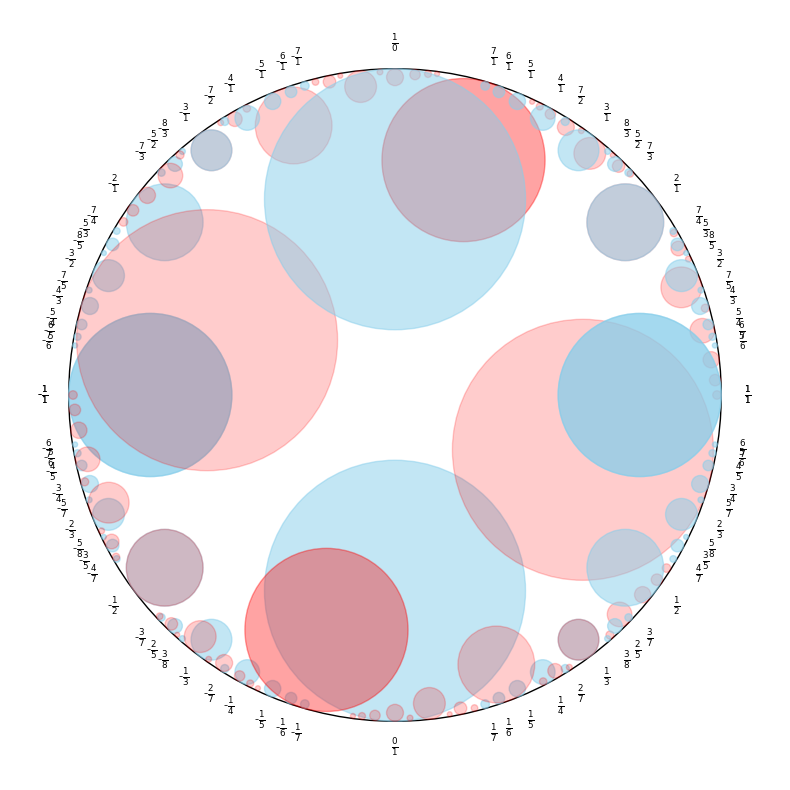

In [100]:
# housekeeping
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect('equal')
ax.set_xlim(-1.18, 1.18)
ax.set_ylim(-1.18, 1.18)
ax.axis('off')

# draw the unit circle and a diameter
add_circle(ax, 0,0,1, fill=False)
#ax.plot([0,0], [1,-1],'.7')


farey_seq  = farey(6).T
#map fractions to the circle this is actually Cayley transform
p,q = farey_seq
Z = (1J*p + q)/(p + 1J*q)

from matplotlib.collections import LineCollection

# Collect all arcs across Farey levels
arcs = []
level = Z
# 
while len(level) > 200: #2:
    for a, b in zip(level, level[1:]):
        pts = geodesic_arc(a, b)
        if pts is not None:
            arcs.extend([pts, -pts])  # both halves of the disc
    level = level[::2]

ax.add_collection(LineCollection(arcs, colors="0.4", linewidths=0.5))


#this is the label string
rlabel = r"{}$\frac{{{}}}{{{}}}$"
#rotation factor
m,n = 1,2
w_rot = (m + n*1J)**4/(m**2 + n**2)**2
for p, q  in farey_seq.T:
    
    # no big denominators
    if q > 8: continue
    z = (1J*p + q)/(p + 1J*q)
    
    #I don'y know if this is clearer but it works
    sign, p = '-' if p < 0 else '', abs(p)
    labels = [ (rlabel.format(sign, p,q), z),
               (rlabel.format(sign, q,p), z.conjugate())]
    for label, w in labels:
        ww = 1.08*w
        ax.annotate(label,
                    xy=(ww.real, ww.imag), 
                    xytext=(0,0),
                    textcoords='offset points', ha='center', va='center',
                    fontsize=9
                    )
        n = p**2 + q**2
        #r = 1/(n + 1)  # Ford circles
        r = 2/(3*n + 2)
        w = (1 - r)*w 
        add_circle(
            ax, w.real, w.imag, r, 
            fill=True, color='skyblue', alpha=.5,
            linewidth=1)
        #continue
        w *= w_rot
        #w *= (2 - 3J)**4/13**2
        #w *= (2 + 5J)**4/29**2
        #w *= (4 - 5J)**4/41**2
        #w *= (3 + 7J)**4/58**2
        #w *= (1  + 4J)**4/17**2 # tricky 17 | 34 which is Markoff
        #w *= (1 + 1J)**4/2**2
        add_circle(
            ax, w.real, w.imag, r, 
            fill=True, color='r', alpha=.2,
            linewidth=1)


    pts = np.array([
            -1.5867260055382615,
             ]) 
    
    for x in pts:
        continue
        lw = .25
        zz = np.array([cayley(x), cayley(-1/x)])
        ax.plot(zz.real,zz.imag,'r',linewidth=lw)

    
plt.tight_layout()

plt.savefig(f'rotate_{m}+{n}i_.png')

In [38]:
p, q  = 1, 1
(p + 1J*q)/(p - 1J*q),

1j

In [89]:
(1 + 1J)**4/2**2

(-1+0j)

In [88]:
(1 + 1J)**4/2**2

(-1+0j)

In [97]:
(1 + 1J)*(1+4J)

(-3+5j)